## Load the dataset from your VS Code project folder

Keep the extracted `train/` and `test/` folders beside this notebook. If they are missing, place `archive.zip` beside the notebook; the next cell will extract it.

In [1]:
from pathlib import Path

project_dir = Path.cwd()
train_dir = project_dir / "train"
test_dir = project_dir / "test"
archive_path = project_dir / "archive.zip"

print(f"Project folder: {project_dir}")

Project folder: d:\techpanda\cnn


## Extract the local archive only if needed

In [2]:
import zipfile

if not (train_dir.is_dir() and test_dir.is_dir()):
    if not archive_path.is_file():
        raise FileNotFoundError(
            f"Expected train/ and test/ folders or a dataset archive at {archive_path}"
        )
    with zipfile.ZipFile(archive_path) as archive:
        archive.extractall(project_dir)

if not (train_dir.is_dir() and test_dir.is_dir()):
    raise FileNotFoundError("The archive must contain train/ and test/ folders.")

## Import Libraries

In [3]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [4]:
train_datagenerator = ImageDataGenerator(rescale=1./255)
train_data = train_datagenerator.flow_from_directory(train_dir,
                                                      target_size = (64, 64),
                                                      batch_size = 32,
                                                      class_mode = 'binary')

test_datagenerator = ImageDataGenerator(rescale=1./255)
test_data = test_datagenerator.flow_from_directory(test_dir,
                                                      target_size = (64, 64),
                                                      batch_size = 32,
                                                      class_mode = 'binary')

Found 20000 images belonging to 2 classes.
Found 5000 images belonging to 2 classes.


In [5]:
from tensorflow.keras.layers import Conv2D

In [6]:
# Initialising the CNN
cnn = tf.keras.models.Sequential()

# Step 1 - Convolution
cnn.add(tf.keras.layers.Conv2D(filters=32,padding="same",kernel_size=3, activation='relu', input_shape=[64, 64, 3]))

# Step 2 - Pooling
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

# Adding a second convolutional layer
cnn.add(tf.keras.layers.Conv2D(filters=32,padding='same',kernel_size=3, activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

# Step 3 - Flattening
cnn.add(tf.keras.layers.Flatten())

# Step 4 - Full Connection
cnn.add(tf.keras.layers.Dense(units=128, activation='relu'))

# Step 5 - Output Layer
cnn.add(tf.keras.layers.Dense(units=1, activation='sigmoid'))

c:\Users\Dell\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [7]:
cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,058,977 (4.04 MB)

 Trainable params: 1,058,977 (4.04 MB)

 Non-trainable params: 0 (0.00 B)

### Complie and fit the CNN

In [8]:
cnn.compile(optimizer = 'adam', loss = 'binary_crossentropy', metrics = ['accuracy'])

In [9]:
cnn.fit(x = train_data, validation_data = test_data, epochs = 10)

Epoch 1/10


625/625 ━━━━━━━━━━━━━━━━━━━━ 174s 273ms/step - accuracy: 0.6812 - loss: 0.5859 - val_accuracy: 0.7704 - val_loss: 0.4911
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 124s 199ms/step - accuracy: 0.7670 - loss: 0.4833 - val_accuracy: 0.7656 - val_loss: 0.4822
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 156s 250ms/step - accuracy: 0.7982 - loss: 0.4272 - val_accuracy: 0.7872 - val_loss: 0.4488
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 119s 117ms/step - accuracy: 0.8257 - loss: 0.3809 - val_accuracy: 0.8048 - val_loss: 0.4289
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 72s 115ms/step - accuracy: 0.8603 - loss: 0.3175 - val_accuracy: 0.8032 - val_loss: 0.4320
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 88s 140ms/step - accuracy: 0.8931 - loss: 0.2525 - val_accuracy: 0.8088 - val_loss: 0.4637
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 64s 103ms/step - accuracy: 0.9316 - loss: 0.1717 - val_accuracy: 0.8018 - val_loss: 0.5209
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 64s 102ms/step - accuracy: 0.9651 - loss: 0.1010 -

### Predict new images

In [10]:
import numpy as np
from tensorflow.keras.preprocessing import image

In [11]:
test_img = image.load_img('dog_1.jpg', target_size=(64,64))
test_img = image.img_to_array(test_img)
test_img = test_img/255
test_img = np.expand_dims(test_img, axis=0)
result = cnn.predict(test_img)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step


In [12]:
result
if result[0]<=0.5:
    print("The image classified is cat")
else:
    print("The image classified is dog")

The image classified is dog


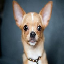

In [16]:
test_img = image.load_img('dog_1.jpg', target_size=(64,64))
test_img

In [13]:
test_img = image.load_img('cat1.jpg', target_size=(64,64))
test_img = image.img_to_array(test_img)
test_img = test_img/255
test_img = np.expand_dims(test_img, axis=0)
result = cnn.predict(test_img)
result

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 174ms/step


array([[0.00059023]], dtype=float32)

In [14]:
if result[0]<=0.5:
    print("The image classified is cat")
else:
    print("The image classified is dog")

The image classified is cat


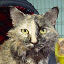

In [18]:
test_img = image.load_img('cat_test.jpg', target_size=(64,64))
test_img